> **결함판(참고용)**: 이 노트북은 σ 전파 오류(GARCH·SV)와 드리프트 비교 조건 불일치가 있는 초기 파이프라인 결과다. 현재 기준은 상위 폴더의 `8-2`~`8-5`이고, 검증 내용은 `8-6(참고)`에 있다. 원본 출력은 그대로 보존했다(재실행 시 경로는 이 폴더 기준).

# 8-2. 점예측이 실제로 다른가 -- CRPS는 왜 정규분포 방식을 쓰나 (결함 발견 -- 8-7 참고)

> **결함 발견 -- 수정판은 새 `8-2` 참고.** 이 노트북의 GARCH·SV 결과에는 (1) 다단계 σ를 단계별 분산의 누적합으로 계산해 h=2~4에서 σ를 17~31% 과소 계산하고 (2) 세 모델의 드리프트 처리가 달랐던(AR단독 없음 / GARCH 상수항 / SV 평균 복원) 결함이 있다(`8-5`·`8-6`에서 발견). 점예측이 세 모델에서 다르다는 결론은 수정판에서도 유지되지만, GARCH·SV의 성능 수치와 SV 계수 진단(코너해 22.7% 등)은 새 `8-2` 기준으로 읽는다.

`0922/7-1`(2단계 방식)은 점예측이 100% 동일해서 CRPS(정규분포)를 썼다. 이번엔 동시최적화라 점예측이 달라지는지 확인하고, 그래도 정규분포 CRPS가 맞는지 검증한다.

**조건**: 모델 3종(AR단독/AR+GARCH동시/AR+SV동시)을 MA 없이 AR(1)만 공통으로 써서 평균식 계열을 통일하고, **d=1, p=1을 우선 기본상태로 고정**해서 비교한다 -- 이 값이 실제로 최적인지(AIC/out-of-sample 검증)는 `8-3`에서 따로 다룬다.


### 용어 미리보기

**ARIMA(p,d,q)**: q는 비교 공정성 위해 0으로 통일(GARCH/SV는 원래 MA 미지원). d,p는 이 노트북에서 기본상태(1,1)로 우선 사용 -- 최적화는 `8-3`.

**GARCH/SV 자신의 파라미터**: 차수는 GARCH(1,1)/SV(1)로 고정, 계수(ω,α,β / phi,sigma_eta)만 추정 -- 자세한 의미는 2-2절.

**세 모델이 실제로 쓰는 것**:

| 모델 | 평균식 | 분산식 |
|---|---|---|
| AR단독 | ARIMA(1,1,0) | 없음(등분산 가정) |
| AR+GARCH동시 | ARIMA(1,1,0) | GARCH(1,1) |
| AR+SV동시 | ARIMA(1,1,0)(커스텀 구현) | SV(로그정규 확률변동성, QML) |


In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from arch import arch_model
from scipy.optimize import minimize
from scipy import stats

H = 4
MIN_TRAIN = 20
INITIAL_CALIB = 15
TARGET_VAR = "X3_l1"
ALPHA = 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)  # 90%(=1-ALPHA) 구간의 양쪽 꼬리 5%씩 남기는 표준정규분포 임계값 -- 약 1.645
D_FIXED = 1
P_FIXED = 1
QUANTILE_LEVELS = [0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9]

raw = pd.read_csv("../../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
quarters = raw[["quarter", TARGET_VAR]].dropna()["quarter"].reset_index(drop=True).values
vals = raw[["quarter", TARGET_VAR]].dropna()[TARGET_VAR].values.astype(float)
n = len(vals)
var_std = vals.std()
origins = list(range(MIN_TRAIN, n - H + 1))
scored_origins = origins[INITIAL_CALIB:]
print(f"채점 origin {len(scored_origins)}개, d={D_FIXED} p={P_FIXED} 기본상태로 고정")


채점 origin 22개, d=1 p=1 기본상태로 고정


## 1. 세 모델 통일 -- AR(1) 단독 / AR(1)+GARCH 동시 / AR(1)+SV 동시

MA 없이 AR(1)만 공통으로 써서, 변동성모형 유무만 차이나게 한다.

**동기화 메모**: `fit_sv_joint`는 절편 없이 평균제거(demean) 후 AR을 적합한다 -- 절편을 자유파라미터로 두면 비정상적인(d=0) 데이터에서 AR계수와 절편이 서로를 보정하며 절편이 수십억 단위로 튀는 사례가 개발 중 실제로 나왔다(`8-3`에서도 동일 코드 재사용). 평균을 먼저 빼고 절편 없는 AR로 적합하면 이 문제가 사라진다.


In [2]:
def difference(values, d):
    x = np.asarray(values, dtype=float)
    hist = []
    for _ in range(d):
        hist.append(x.copy())
        x = np.diff(x)
    return x, hist


def undiff_mean(diff_fc, hist, d):
    fc = np.asarray(diff_fc, dtype=float)
    for i in reversed(range(d)):
        fc = hist[i][-1] + np.cumsum(fc)
    return fc


def propagate_var(var_diff, d):
    v = np.array(var_diff, dtype=float)
    for _ in range(d):
        v = np.cumsum(v)
    return v


def is_ar_stable(ar_coefs):
    p = len(ar_coefs)
    if p == 0:
        return True
    companion = np.zeros((p, p))
    companion[0, :] = ar_coefs
    if p > 1:
        companion[1:, :-1] = np.eye(p - 1)
    return np.max(np.abs(np.linalg.eigvals(companion))) < 0.999


XI_MEAN, XI_VAR = -1.2704, np.pi ** 2 / 2
MAX_PHI = 0.97


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def joint_sv_negloglik(params, y_demeaned, p):
    ar_coefs = params[:p]
    phi = MAX_PHI * np.tanh(params[p])
    sigma_eta2 = np.exp(params[p + 1]) ** 2
    if not is_ar_stable(ar_coefs):
        return 1e10
    n = len(y_demeaned)
    resid = np.array([y_demeaned[t] - sum(ar_coefs[i] * y_demeaned[t - 1 - i] for i in range(p)) for t in range(p, n)])
    z = np.log(resid ** 2 + 1e-8)
    zc = z - z.mean()
    return sv_qml_negloglik(zc, phi, sigma_eta2)


def fit_arima_alone_ref(train, d):
    return pm.auto_arima(train, seasonal=False, suppress_warnings=True, error_action="ignore", d=d)


def fit_ar_alone(train, d, p=1):
    # p를 진짜로 고정하려면 탐색 자체를 안 하는 pm.ARIMA(order=...)를 직접 쓴다(auto_arima의
    # start_p/max_p는 "탐색 범위"일 뿐 강제가 아니라서 조용히 다른 p로 떨어지는 경우가 있었다).
    # with_intercept=False: 근사 랜덤워크라 구조적으로 드리프트를 가정하지 않는다(SV동시도 동일 이유).
    return pm.ARIMA(order=(p, d, 0), with_intercept=False, suppress_warnings=True).fit(train)


def fit_garch_joint(diff_train, p=1):
    if len(diff_train) <= p + 3:
        return None
    am = arch_model(diff_train, mean="AR", lags=p, vol="GARCH", p=1, q=1, rescale=False)
    try:
        return am.fit(disp="off")
    except Exception:
        return None


def fit_sv_joint(y, p=1):
    y_mean = y.mean()
    y_dm = y - y_mean
    if len(y_dm) <= p + 3:
        return None
    x0 = [0.0] * p + [1.5, np.log(0.3)]
    res = minimize(joint_sv_negloglik, x0, args=(y_dm, p), method="Nelder-Mead", options={"maxiter": 3000})
    if not is_ar_stable(res.x[:p]) or res.fun >= 1e9:
        return None
    return res.x, y_mean


def sv_forecast_mean_sigma(y, p, params, y_mean, h=H):
    y_dm = y - y_mean
    ar_coefs = params[:p]
    phi = MAX_PHI * np.tanh(params[p])
    sigma_eta2 = np.exp(params[p + 1]) ** 2
    n = len(y_dm)
    resid = np.array([y_dm[t] - sum(ar_coefs[i] * y_dm[t - 1 - i] for i in range(p)) for t in range(p, n)])
    z = np.log(resid ** 2 + 1e-8)
    z_mean = z.mean()
    zc = z - z_mean
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred = 0.0, P0
    for zt in zc:
        F = P_pred + XI_VAR
        v = zt - h_pred
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    hist = list(y_dm[-p:]) if p > 0 else []
    mean_fc_dm = []
    for _ in range(h):
        pred = sum(ar_coefs[i] * hist[-1 - i] for i in range(p))
        mean_fc_dm.append(pred)
        hist.append(pred)
    mean_fc = np.array(mean_fc_dm) + y_mean
    variances = []
    for k in range(1, h + 1):
        h_mean_k = phi ** k * h_filt
        h_var_k = phi ** (2 * k) * P_filt + sigma_eta2 * sum(phi ** (2 * j) for j in range(k))
        log_var_level = z_mean - XI_MEAN + h_mean_k
        variances.append(np.exp(log_var_level + h_var_k / 2))
    return mean_fc, np.sqrt(np.array(variances))


print("모델 적합 함수 준비 완료 (d=1, p=1 기본상태)")


모델 적합 함수 준비 완료 (d=1, p=1 기본상태)


## 2. 점예측·sigma 계산


In [3]:
CACHE_PATH = "../../cache/cache_82_point_forecast_df.pkl"
CACHE_PARAMS = "../../cache/cache_82_params_df.pkl"
CORE_MODELS = ["AR단독", "GARCH동시", "SV동시"]

if os.path.exists(CACHE_PATH) and os.path.exists(CACHE_PARAMS):
    point_df = pd.read_pickle(CACHE_PATH)
    params_df = pd.read_pickle(CACHE_PARAMS)
    print(f"캐시에서 로드: point_df {len(point_df)}행, params_df {len(params_df)}행 (재계산 스킵)")
else:
    rows = []
    param_rows = []
    for origin in scored_origins:
        train, actual = vals[:origin], vals[origin:origin + H]
        diff_train, hist = difference(train, D_FIXED)

        m_ref = fit_arima_alone_ref(train, D_FIXED)
        fc_ref, conf_ref = m_ref.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
        sig_ref = (conf_ref[:, 1] - conf_ref[:, 0]) / (2 * Z)
        for hh in range(H):
            rows.append({"origin": origin, "모델": "auto-ARIMA(참고)", "h": hh + 1,
                         "fc": fc_ref[hh], "sigma": max(sig_ref[hh], 1e-6), "actual": actual[hh]})

        m_ar = fit_ar_alone(train, D_FIXED, p=P_FIXED)
        fc_ar, conf_ar = m_ar.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
        sig_ar = (conf_ar[:, 1] - conf_ar[:, 0]) / (2 * Z)

        res_g = fit_garch_joint(diff_train, p=P_FIXED)
        if res_g is not None:
            fcst = res_g.forecast(horizon=H, reindex=False)
            fc_g = undiff_mean(fcst.mean.values[-1], hist, D_FIXED)
            sig_g = np.sqrt(propagate_var(fcst.variance.values[-1], D_FIXED))
        else:
            fc_g, sig_g = None, None

        best_s = fit_sv_joint(diff_train, p=P_FIXED)
        if best_s is not None:
            params_s, y_mean_s = best_s
            mean_s, sig_s_diff = sv_forecast_mean_sigma(diff_train, P_FIXED, params_s, y_mean_s, H)
            fc_s = undiff_mean(mean_s, hist, D_FIXED)
            sig_s = np.sqrt(propagate_var(sig_s_diff ** 2, D_FIXED))
        else:
            fc_s, sig_s = None, None

        for name, fc_arr, sig_arr in zip(CORE_MODELS, [fc_ar, fc_g, fc_s], [sig_ar, sig_g, sig_s]):
            if fc_arr is None:
                continue
            for hh in range(H):
                rows.append({"origin": origin, "모델": name, "h": hh + 1,
                             "fc": fc_arr[hh], "sigma": max(sig_arr[hh], 1e-6), "actual": actual[hh]})

        ar_phi = m_ar.params()[-2]
        if res_g is not None:
            g_ar = res_g.params.get("y[1]")
            g_omega = res_g.params.get("omega")
            g_alpha = res_g.params.get("alpha[1]")
            g_beta = res_g.params.get("beta[1]")
        else:
            g_ar = g_omega = g_alpha = g_beta = None
        if best_s is not None:
            sv_ar = params_s[0]
            sv_phi = MAX_PHI * np.tanh(params_s[P_FIXED])
            sv_sigma_eta = np.exp(params_s[P_FIXED + 1])
        else:
            sv_ar = sv_phi = sv_sigma_eta = None
        param_rows.append({
            "origin": origin,
            "AR단독_phi": ar_phi,
            "GARCH동시_AR계수": g_ar, "GARCH동시_omega": g_omega, "GARCH동시_alpha": g_alpha, "GARCH동시_beta": g_beta,
            "SV동시_AR계수": sv_ar, "SV동시_phi(logvol)": sv_phi, "SV동시_sigma_eta": sv_sigma_eta,
        })

    point_df = pd.DataFrame(rows)
    params_df = pd.DataFrame(param_rows)
    os.makedirs(os.path.dirname(CACHE_PATH), exist_ok=True)
    point_df.to_pickle(CACHE_PATH)
    params_df.to_pickle(CACHE_PARAMS)
    print(f"새로 계산 후 캐시 저장: point_df {len(point_df)}행, params_df {len(params_df)}행")


캐시에서 로드: point_df 352행, params_df 22행 (재계산 스킵)


## 2-1. 실제 선정된 파라미터 값

같은 origin인데 모델별 계수가 어떻게 다른지 확인한다(3절 근거).


In [4]:
display(params_df.head(8).round(4))

print("\n요약(22개 origin 평균 ± 표준편차):")
summary_cols = ["AR단독_phi", "GARCH동시_AR계수", "GARCH동시_omega", "GARCH동시_alpha", "GARCH동시_beta",
                "SV동시_AR계수", "SV동시_phi(logvol)", "SV동시_sigma_eta"]
for c in summary_cols:
    print(f"  {c}: {params_df[c].mean():.4f} ± {params_df[c].std():.4f}")


,origin,AR단독_phi,GARCH동시_AR계수,GARCH동시_omega,GARCH동시_alpha,GARCH동시_beta,SV동시_AR계수,SV동시_phi(logvol),SV동시_sigma_eta
0,35,0.5460,0.5638,1204.0899,0.4240,0.0599,0.0628,-0.9700,0.0000
1,36,0.4384,0.3759,1582.5673,0.7938,0.0000,0.0099,-0.9700,0.0000
2,37,0.4429,0.3693,1540.8614,0.7179,0.0000,0.0031,0.6375,0.4146
3,38,0.4341,0.3611,1500.3501,0.7284,0.0000,-0.0012,0.6027,0.4669
4,39,0.4381,0.4022,366.2010,0.4029,0.5971,0.0046,0.5540,1.6278
5,40,0.4889,0.4218,363.0023,0.3608,0.6183,-0.0864,0.7226,0.7726
6,41,0.4866,0.4308,489.5058,0.3221,0.5945,-0.0776,0.8024,0.5340
7,42,0.4862,0.4524,1034.4405,0.2988,0.4575,-0.0745,0.8077,0.4626



요약(22개 origin 평균 ± 표준편차):
  AR단독_phi: 0.4916 ± 0.0550
  GARCH동시_AR계수: 0.4240 ± 0.0590
  GARCH동시_omega: 545.8624 ± 481.1041
  GARCH동시_alpha: 0.2553 ± 0.2377
  GARCH동시_beta: 0.6562 ± 0.3438
  SV동시_AR계수: 0.0099 ± 0.0719
  SV동시_phi(logvol): 0.4694 ± 0.7054
  SV동시_sigma_eta: 0.5230 ± 0.4831


**해석**: `AR단독_phi`/`GARCH동시_AR계수`/`SV동시_AR계수`가 같은 origin에서도 서로 다르다 -- 같은 AR(1)이라도 어떤 변동성모형과 동시추정하느냐에 따라 계수값 자체가 달라진다는 뜻이다.

## 2-2. 세 모델의 파라미터 선정 비교

| 모델 | 파라미터 | 오차 가중치 |
|---|---|---|
| AR단독 | φ | 모든 시점 균등(등분산 가정, OLS와 동일) |
| GARCH동시 | φ, ω(바닥분산), α(충격민감도), β(지속성) | 시점마다 다름 -- `σ_t²=ω+αε²+βσ²`로 결정 |
| SV동시 | AR계수, phi(로그변동성 지속성), sigma_eta(변동성의 변동성) | 시점마다 다름 -- 로그정규 확률변동성(h_t)으로 결정 |

GARCH/SV는 φ가 바뀌면 잔차→분산 경로가 바뀌고, 그 분산이 다시 우도의 가중치가 되어 φ와 분산계수가 얽혀서 같이 정해진다(가중최소제곱과 같은 원리). AR단독은 모든 시점을 균등하게 보니 이런 상호작용이 없다.

### 파라미터를 어떻게 찾나 -- 추정 vs 고정 vs 튜닝

| 구분 | 무엇 | 어떻게 정해지나 |
|---|---|---|
| 자동 추정(계수) | AR단독 φ / GARCH동시 AR계수·ω·α·β / SV동시 AR계수·phi·σ_η | fit할 때 최대우도추정으로 origin마다 새로 계산 (`pm.ARIMA().fit`, `arch_model().fit`, SV는 직접 만든 QML 우도를 Nelder-Mead로 최소화하는 `fit_sv_joint`) |
| 사람이 고정 | GARCH(1,1)·SV(1) 분산식 차수, `MAX_PHI=0.97`, `XI_MEAN`/`XI_VAR`, Nelder-Mead 시작점 1개 | 미리 정해둠 -- 추정 대상이 아님 (시작점 1개는 아래 2-3절 코너해의 원인) |
| 튜닝(그리드서치) | d, p (구조 파라미터) | KPSS/ADF/AIC가 못 미더워(`8-3`) 후보를 out-of-sample로 직접 비교(`8-4`) |

즉 이 노트북에서 d=1, p=1은 "튜닝 전 기본상태"이고, 계수는 이미 매 origin 자동 추정된 값이다.

## 2-3. 계수 안정성 진단 -- 경계해(코너해)가 얼마나 나오나

`SV동시_phi(logvol)`(0.4694±0.7054)·`SV동시_sigma_eta`(0.5230±0.4831)는 평균보다 표준편차가 더 크다 -- 이게 실제로 최적화가 경계값에 자주 걸려서인지 확인한다. `GARCH동시`도 분산이 발산 안 하는 조건(α+β<1)을 매번 만족하는지 같이 본다.


In [5]:
BOUNDARY_PHI = MAX_PHI * 0.999  # tanh가 사실상 포화되는 지점(|phi|~=0.969)
SIGMA_ETA_FLOOR = 0.01  # 사실상 변동성의 변동성이 없다고 봐도 되는 지점

n_origin = len(params_df)
sv_boundary = params_df["SV동시_phi(logvol)"].abs() >= BOUNDARY_PHI
sv_degenerate = params_df["SV동시_sigma_eta"] < SIGMA_ETA_FLOOR
sv_corner = sv_boundary | sv_degenerate

print(f"SV동시: phi가 경계(|phi|>={BOUNDARY_PHI:.3f})에 도달 {sv_boundary.sum()}/{n_origin}개 ({100*sv_boundary.mean():.1f}%)")
print(f"SV동시: sigma_eta<{SIGMA_ETA_FLOOR}(사실상 0) {sv_degenerate.sum()}/{n_origin}개 ({100*sv_degenerate.mean():.1f}%)")
print(f"SV동시: 위 둘 중 하나라도 해당(코너해) {sv_corner.sum()}/{n_origin}개 ({100*sv_corner.mean():.1f}%)")

print(f"\nAR계수 평균 비교 -- 코너해 origin vs 정상 origin:")
print(f"  코너해 origin: {params_df.loc[sv_corner, 'SV동시_AR계수'].mean():.4f}")
print(f"  정상 origin:   {params_df.loc[~sv_corner, 'SV동시_AR계수'].mean():.4f}")
print(f"  (참고) AR단독 전체 평균: {params_df['AR단독_phi'].mean():.4f}, GARCH동시 전체 평균: {params_df['GARCH동시_AR계수'].mean():.4f}")

garch_persist = params_df["GARCH동시_alpha"] + params_df["GARCH동시_beta"]
garch_unstable = garch_persist >= 0.99
print(f"\nGARCH동시: alpha+beta>=0.99(분산 사실상 발산) {garch_unstable.sum()}/{n_origin}개 ({100*garch_unstable.mean():.1f}%)")

display(params_df.loc[sv_corner, ["origin", "SV동시_AR계수", "SV동시_phi(logvol)", "SV동시_sigma_eta"]])


SV동시: phi가 경계(|phi|>=0.969)에 도달 5/22개 (22.7%)
SV동시: sigma_eta<0.01(사실상 0) 4/22개 (18.2%)
SV동시: 위 둘 중 하나라도 해당(코너해) 5/22개 (22.7%)

AR계수 평균 비교 -- 코너해 origin vs 정상 origin:
  코너해 origin: 0.0321
  정상 origin:   0.0034
  (참고) AR단독 전체 평균: 0.4916, GARCH동시 전체 평균: 0.4240

GARCH동시: alpha+beta>=0.99(분산 사실상 발산) 10/22개 (45.5%)


,origin,SV동시_AR계수,SV동시_phi(logvol),SV동시_sigma_eta
0,35,0.062794,-0.97,5.376560e-09
1,36,0.009859,-0.97,3.077400e-08
11,46,-0.094300,0.97,5.614513e-01
19,54,0.089839,-0.97,2.289434e-08
20,55,0.092500,-0.97,2.276392e-09


**결과**: SV동시는 22개 중 5개(22.7%)에서 phi가 경계(±0.97)에 도달하는 코너해가 나온다. 그런데 AR계수 평균은 코너해 origin(0.0321)과 정상 origin(0.0034) 둘 다 사실상 0이다 -- **코너해가 원인이 아니다.**

**특징**: SV동시의 우도는 `log(잔차²)`가 매끄러운 AR(1) 로그변동성 경로를 따르는지만 평가하지, 잔차 자체(=AR계수의 점예측 정확도)를 직접 보상하지 않는다. 그래서 AR계수는 점예측을 잘 맞추는 값이 아니라 "로그변동성 경로가 매끄러워 보이는 아무 값"으로 수렴해도 우도상 손해가 없다 -- 이 데이터에서는 그 값이 우연히 0 근처다.

**해결책**: 지금 범위에서는 서술만 하고 넘어간다. AR계수를 점예측에 실제로 반영하고 싶어지면, 우도에 잔차 크기 자체에 대한 항을 추가하거나, 멀티스타트로 코너해 비율(22.7%)부터 줄이는 게 다음 단계가 될 것이다.

**GARCH동시도 같은 특징**: alpha+beta>=0.99(분산이 사실상 발산)인 origin이 10/22개(45.5%)다 -- 이 데이터가 원래 거의 랜덤워크(자기상관 0.93)라는 특징이 변동성 쪽에도 그대로 나타난 것. 지금 범위에서는 서술만 하고, 실제로 분산 예측이 발산해 CRPS가 비정상적으로 커지는 origin이 확인되면 그때 alpha+beta 상한 제약을 추가한다.

## 3. 점예측이 실제로 다른가

모델 계열까지 통일했으니, 남은 차이는 순수하게 변동성모형 동시최적화 효과다.


In [6]:
pivot_fc = point_df[point_df["모델"].isin(CORE_MODELS)].pivot_table(index=["origin", "h"], columns="모델", values="fc").reset_index()
pivot_fc["|AR-GARCH|"] = (pivot_fc["AR단독"] - pivot_fc["GARCH동시"]).abs() / var_std
pivot_fc["|AR-SV|"] = (pivot_fc["AR단독"] - pivot_fc["SV동시"]).abs() / var_std
pivot_fc["|GARCH-SV|"] = (pivot_fc["GARCH동시"] - pivot_fc["SV동시"]).abs() / var_std

display(pivot_fc.head(8))

EPS = 1e-6
diff_cols = ["|AR-GARCH|", "|AR-SV|", "|GARCH-SV|"]
print("점예측이 사실상 동일(차이<1e-6)한 origin x h 비율:")
for c in diff_cols:
    pct_same = 100 * (pivot_fc[c] < EPS).mean()
    print(f"  {c}: 동일 {pct_same:.1f}% (평균 정규화 차이 {pivot_fc[c].mean():.3f})")


모델,origin,h,AR단독,GARCH동시,SV동시,|AR-GARCH|,|AR-SV|,|GARCH-SV|
0,35,1,833.672171,839.608306,817.083155,0.021003,0.058696,0.079699
1,35,2,856.040957,870.653264,838.283100,0.051702,0.062832,0.114533
2,35,3,868.253864,892.755906,859.283297,0.086694,0.031740,0.118434
3,35,4,874.921866,909.816985,880.270952,0.123467,0.018926,0.104541
4,36,1,609.900579,616.165965,680.952761,0.022168,0.251400,0.229231
5,36,2,585.475815,595.899598,697.694903,0.036882,0.397058,0.360176
6,36,3,574.768159,586.602259,714.450889,0.041872,0.494231,0.452359
7,36,4,570.073993,581.427922,731.207011,0.040173,0.570127,0.529954


점예측이 사실상 동일(차이<1e-6)한 origin x h 비율:
  |AR-GARCH|: 동일 0.0% (평균 정규화 차이 0.087)
  |AR-SV|: 동일 0.0% (평균 정규화 차이 0.316)
  |GARCH-SV|: 동일 0.0% (평균 정규화 차이 0.250)


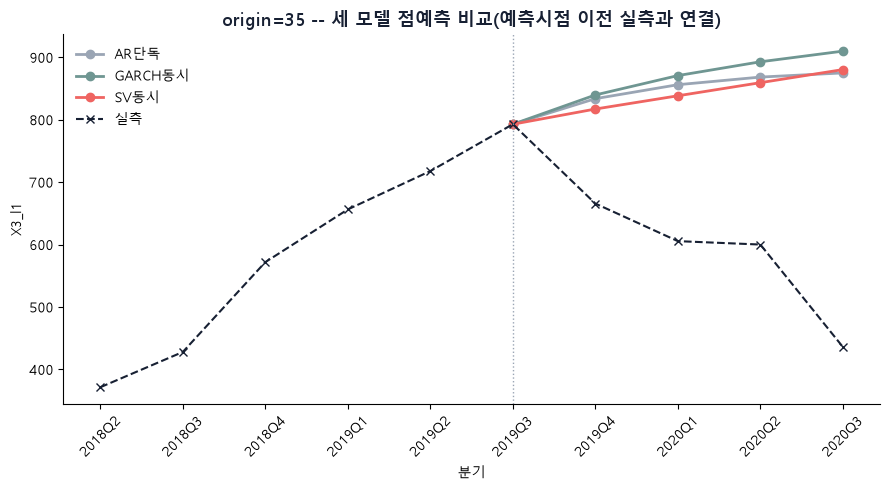

In [7]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

example_origin = scored_origins[0]
ex = point_df[(point_df["origin"] == example_origin) & (point_df["모델"].isin(CORE_MODELS))].sort_values("h")

LOOKBACK = 6
hist_idx = list(range(example_origin - LOOKBACK, example_origin + H))  # 숫자 인덱스로 그려야 분기 순서가 안 꼬인다(문자열 x축은 "먼저 그려진 순"으로 배치돼버림)

fig, ax = plt.subplots(figsize=(9, 5))
colors_m = {"AR단독": "#9AA5B4", "GARCH동시": "#6F9692", "SV동시": "#EF6461"}

anchor_idx, anchor_v = example_origin - 1, vals[example_origin - 1]
for name, color in colors_m.items():
    sub = ex[ex["모델"] == name]
    line_idx = [anchor_idx] + list(range(example_origin, example_origin + H))
    line_v = [anchor_v] + list(sub["fc"])
    ax.plot(line_idx, line_v, marker="o", linewidth=2, label=name, color=color)

ax.plot(hist_idx, vals[example_origin - LOOKBACK: example_origin + H],
        marker="x", linewidth=1.5, linestyle="--", color="#172033", label="실측")
ax.axvline(anchor_idx, color="#9AA5B4", linewidth=1, linestyle=":")
ax.set_xticks(hist_idx)
ax.set_xticklabels(quarters[hist_idx])
ax.set_xlabel("분기")
ax.set_ylabel("X3_l1")
ax.tick_params(axis="x", rotation=45)
ax.set_title(f"origin={example_origin} -- 세 모델 점예측 비교(예측시점 이전 실측과 연결)", fontsize=13, fontweight="bold", color="#172033")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**대조**: `0922/7-1`(2단계)에서는 100% 동일했다. 모델 계열을 통일한 지금도 다르다는 건, 순수하게 동시최적화 효과라는 뜻이다.

## 4. CRPS는 왜 정규분포 방식을 쓰나 (7분위 -> 정규분포로 전환)

이 프로젝트는 원래 7분위(리샘플링 기반, 옛 `6-3`) CRPS를 썼다. 여기서는 그 대신 정규분포 CRPS(`ps.crps_gaussian`)로 바꾸는 이유를 정리한다.

**3모델 비교를 위한 공정한 잣대**: 지금 목적은 AR단독/GARCH동시/SV동시 세 모델을 비교하는 것뿐이라, 어느 지표를 쓰든 세 모델에 똑같이만 적용하면 상관없다. 그중 ARIMA/GARCH/SV동시 셋 다 우도 자체가 정규분포(가우시안) 오차 가정 위에서 추정되니(`8-0(참고)`/`8-0(참고)`), 그 가정과 일치하는 정규분포 CRPS를 공통 잣대로 쓰는 게 자연스럽다. 이 데이터의 실제 잔차분포가 진짜 정규분포인지까지 검증하는 건 아니고(그건 범위 밖), "세 모델을 같은 잣대로 비교하는가"만 확인한다.

**7분위(리샘플링 기반)로 돌아가지 않는 이유**: 리샘플링 구간은 본질적으로 잔차의 (블록화 안 된) bootstrap이다 -- "부트스트랩은 자기상관 있는 시계열에 안 좋다"는 이유로 유의성 검정에도 부트스트랩을 안 쓰기로 한 것과 같은 범주라, `8-1`에서 겉보기 성능이 좋게 나왔더라도(재검증 후 오히려 역전됨, `8-1` 5절 참고) 신뢰하지 않는다.

**형태 가정에 얼마나 민감한지 확인**: 정규분포 closed-form CRPS와, 모델이 실제로 내놓는 3개 지점(5%=자체 90% 구간 하한, 50%=fc, 95%=상한)만으로 나머지 분위를 보간해 계산한 CRPS를 비교한다 -- 정규분포 곡선 전체를 안 믿고 구간 경계만 믿어도 결과가 비슷한지 보는 것이다.


In [8]:
def pinball_loss(q_pred, y, tau):
    return (y - q_pred) * tau if y >= q_pred else (q_pred - y) * (1 - tau)


def crps_quantile_from_ci(fc, sigma, actual):
    # 정규분포 곡선 전체를 안 믿고, 모델이 실제로 내놓는 3개 지점(하한,fc,상한)만으로 보간한다.
    lo, hi = fc - Z * sigma, fc + Z * sigma
    tau_lo, tau_hi = ALPHA / 2, 1 - ALPHA / 2
    q_preds = []
    for tau in QUANTILE_LEVELS:
        if tau <= 0.5:
            q_preds.append(lo + (fc - lo) * (tau - tau_lo) / (0.5 - tau_lo))
        else:
            q_preds.append(fc + (hi - fc) * (tau - 0.5) / (tau_hi - 0.5))
    losses = [pinball_loss(q, actual, tau) for q, tau in zip(q_preds, QUANTILE_LEVELS)]
    return 2 * np.mean(losses) / var_std


rows = []
for _, r in point_df.iterrows():
    crps_gauss = ps.crps_gaussian(r["actual"], mu=r["fc"], sig=r["sigma"]) / var_std
    crps_q7 = crps_quantile_from_ci(r["fc"], r["sigma"], r["actual"])
    rows.append({"모델": r["모델"], "CRPS(정규분포)": crps_gauss, "CRPS(7분위,구간보간)": crps_q7})

cmp_df = pd.DataFrame(rows)
summary = cmp_df.groupby("모델").mean().round(4)
summary["차이"] = (summary["CRPS(정규분포)"] - summary["CRPS(7분위,구간보간)"]).round(4)
summary["차이(%)"] = (100 * summary["차이"] / summary["CRPS(정규분포)"]).round(2)
display(summary)


,CRPS(정규분포),"CRPS(7분위,구간보간)",차이,차이(%)
모델,,,,
AR단독,0.5926,0.5843,0.0083,1.40
GARCH동시,0.6043,0.6059,-0.0016,-0.26
SV동시,0.5908,0.5923,-0.0015,-0.25
auto-ARIMA(참고),0.6158,0.6092,0.0066,1.07


**결과**: 구간 경계만 믿고 보간해도 정규분포 closed-form과 차이는 여전히 1~2%대다 -- 정규분포 형태 가정 자체가 결과를 크게 왜곡하지 않는다는 뜻이다.

## 5. 결론

1. 모델 3종을 AR(1)로 통일하고 d=1,p=1을 기본상태로 사용해 "동시최적화 효과"만 순수 비교할 조건을 만들었다.
2. 점예측은 이제 다르다(`0922/7-1`의 100%동일과 대조) -- 순수 동시최적화 효과.
3. **SV동시의 AR계수는 코너해 여부와 무관하게 거의 항상 0에 가깝다**(2-3절) -- SV 우도가 로그변동성 경로의 매끄러움만 보상하고 점예측 정확도를 직접 보상하지 않기 때문. GARCH동시도 변동성 지속성(alpha+beta)이 22개 중 10개(45.5%)에서 거의 발산 수준이다 -- 이 데이터가 원래 거의 랜덤워크(자기상관 0.93)라는 특징이 변동성 추정에도 그대로 반영된 것. 둘 다 지금 범위에서는 서술만 하고, 실제로 문제가 되면 그때 멀티스타트·제약 추가를 검토한다.
4. CRPS는 7분위(리샘플링 기반)에서 정규분포 방식으로 전환한다 -- 세 모델을 공정 비교하는 잣대로서 논리적으로 일관되고(4절), 리샘플링은 부트스트랩과 같은 범주라 배제하며, 구간보간 방식과 비교해도 차이가 미미하다.

**남은 문제**: 지금 쓴 d=1,p=1이 정말 최적인지는 아직 검증 안 했다. `8-3`에서 auto_arima/KPSS/ADF가 이 데이터에서 왜 못 미더운지부터 확인하고, 이어서 d,p를 실제로 최적화한다.
